<a href="https://colab.research.google.com/github/ashwinkck/SME-1-/blob/main/upes/GenAI/UPES_genai_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Building an AutoEncoder - handwritten digit reconstruction using MNIST

In [2]:
!pip install tensorflow matplotlib numpy. Tra

ERROR: Invalid requirement: 'numpy.': Expected semicolon (after name with no version specifier) or end
    numpy.
         ^


Importing Libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input,Dense

2 - loading the Dataset

In [4]:
(x_train,_), (x_test,_) = mnist.load_data()

print("Training Data:", x_train.shape)
print("Testing Data:",x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)


3 - Visualizing the original images

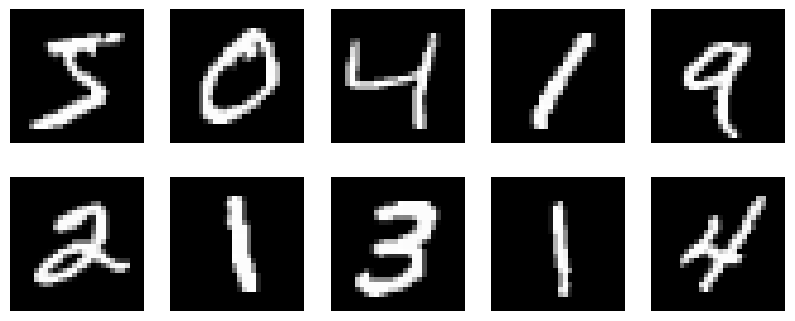

In [5]:
plt.figure(figsize=(10,4))

for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(x_train[i],cmap="gray")
  plt.axis("off")
plt.show()

4 - Preprocessing the images

In [6]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1,784)
x_test = x_test.reshape(-1,784)

print(x_train.shape)

(60000, 784)


5 - Defining the Encoder

In [7]:
input_layer = Input(shape=(784,))

encoded = Dense(128,activation="relu")(input_layer)

latent = Dense(32,activation="relu")(encoded)

6 - Defining the Decoder

In [8]:
decoded = Dense(128,activation="relu")(latent)

output_layer = Dense(784,activation="sigmoid")(decoded)

7 - building the complete autoencoder

In [9]:
autoencoder = Model(input_layer,output_layer)
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

8 - Training the autoencoder

In [10]:
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=5,
    batch_size=256,
    shuffle = True,
    validation_data = (x_test,x_test)
)

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.2298 - val_loss: 0.1489
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1330 - val_loss: 0.1198
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.1154 - val_loss: 0.1104
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - loss: 0.1083 - val_loss: 0.1044
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1041 - val_loss: 0.1008


9 - Plotting the training Loss

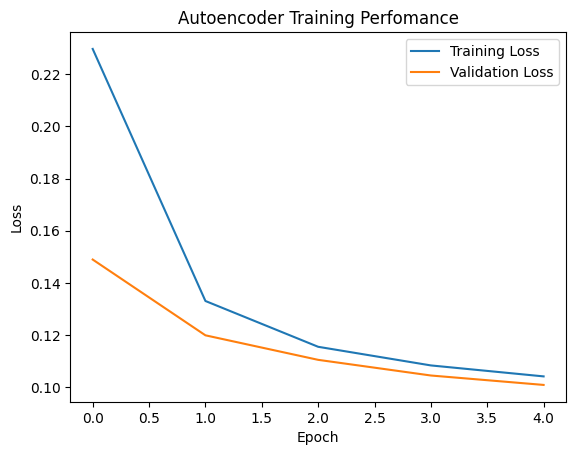

In [12]:
plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"],
         label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Perfomance")
plt.legend()
plt.show()

10 - Generating Reconstructed images

In [13]:
reconstructed = autoencoder.predict(x_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


11 - Comparing og and reconsructed images

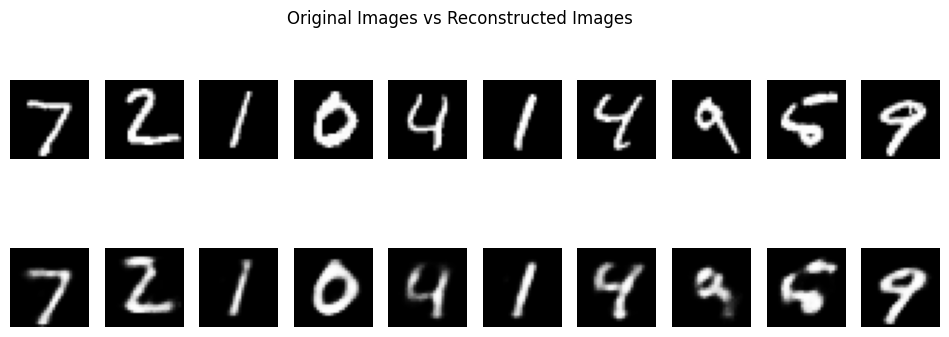

In [14]:
plt.figure(figsize=(12, 4))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Original Images vs Reconstructed Images")
plt.show()